# Comprehensive Benchmarking of Bulk RNA-Seq Quantification Pipelines

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2023-03-28
> - Modified: 2024-07-13

# 1. Experimental Design

> Epigenomic comparison of distinct pluripotent stem cell states reveals a new class of enhancers with roles throughout mammalian development.
> - [GSE57409](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE57409)
> - Factor DC, Corradin O, Zentner GE, Saiakhova A, Song L, Chenoweth JG, McKay RD, Crawford GE, Scacheri PC, Tesar PJ. Epigenomic comparison reveals activation of "seed" enhancers during transition from naive to primed pluripotency. Cell Stem Cell. 2014 Jun 5;14(6):854-63. doi: 10.1016/j.stem.2014.05.005.
> - polyA RNA-seq
> - Illumina HiSeq 2000, PE100
> - mm10

| Sample | Organism | Cell | Source | Strain | Treatment | Replicate |
| - | - | - | - | - | - | - |
| mESC | Mus musculus | mESC | Embryionic stem cell | - | - | rep1~4 |
| mEpiSC | Mus musculus | mESC | Epiblast stem cells | - | - | rep1~4 |

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

### a). STAR

In [ ]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output"

#### (1). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

In [4]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("rep"))) |>
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Replicate
,<fct>,<fct>
mESC_rep1,mESC,rep1
mESC_rep2,mESC,rep2
mESC_rep3,mESC,rep3
mESC_rep4,mESC,rep4
mEpiSC_rep1,mEpiSC,rep1
mEpiSC_rep2,mEpiSC,rep2
mEpiSC_rep3,mEpiSC,rep3
mEpiSC_rep4,mEpiSC,rep4


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("rep")) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [7]:
star_fc_dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Cell)

star_fc_dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

#### (2). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    select("sampleName", "fileName", "Cell", "Replicate") |>
    as.data.frame()

In [10]:
star_ht_dds <- DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Cell, 
    directory = file.path(data_dir, "04_counts"))

star_ht_dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

### b). Hisat2

In [11]:
data_dir <- "~/dataset_2/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/03_output"

#### (1). FeatureCounts

In [12]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^03_output/03_align/(.*?).bam", "\\1", x = _) |> 
    gsub(pattern = "-", replacement = "_")

In [13]:
coldata <- colnames(raw_counts) |>
    tibble(sample = _) |>
    filter(str_detect(sample, fixed("rep"))) |>
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

In [14]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

In [15]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("rep")) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

In [16]:
hisat2_fc_dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Cell)

hisat2_fc_dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

#### (2). HTseq-count

In [17]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

In [18]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    select("sampleName", "fileName", "Cell", "Replicate") |>
    as.data.frame()

In [19]:
hisat2_ht_dds <- DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Cell,
    directory = file.path(data_dir, "04_counts"))

hisat2_ht_dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

### c). Salmon

In [20]:
data_dir <- "~/dataset_2/bulk_omics/rnaseq_Mm_mESC_mEpiSC_GSE57409/02_output"

In [21]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

In [22]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

In [23]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

salmon_quants <- salmon_quants[rownames(coldata)]

In [24]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [25]:
salmon_dds <- DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Cell)
salmon_dds

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

### d). kallisto

In [26]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

In [27]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Replicate = factor(Replicate)) |> 
    arrange(Cell, Replicate) |>
    column_to_rownames("sample")

kallisto_quants <- kallisto_quants[rownames(coldata)]

In [28]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [29]:
kallisto_dds <- DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Cell)
kallisto_dds

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): mESC_rep1 mESC_rep2 ... mEpiSC_rep3 mEpiSC_rep4
colData names(2): Cell Replicate

## 2). Object Construction

In [30]:
dds_list <- list(
    STAR_FC = star_fc_dds, STAR_HT = star_ht_dds,
    HISAT2_FC = hisat2_fc_dds, HISAT2_HT = hisat2_ht_dds,
    Salmon = salmon_dds, Kallisto = kallisto_dds
)

In [31]:
dds_list <- lapply(dds_list, function(dds) {
    dds[rowSums(counts(dds) >= 10) >= 4, ]
})

In [32]:
common_genes <- lapply(dds_list, rownames) |>
    purrr::reduce(intersect)
length(common_genes)

[1] 17088

In [33]:
dds_list <- lapply(dds_list, function(dds) {
    dds[common_genes, ]
})

# 3. Normalization

In [34]:
combined_norms <- lapply(dds_list, function(dds) {
    rlog(dds, blind = FALSE) |> assay()
})

using 'avgTxLength' from assays(dds), correcting for library size

using 'avgTxLength' from assays(dds), correcting for library size



In [35]:
combined_norm <- do.call(cbind, lapply(names(combined_norms), function(name) {
    mat <- combined_norms[[name]][common_genes, ]
    colnames(mat) <- paste(colnames(mat), name, sep = "_")
    return(mat)
}))

# 4. Exploration

### 1). Overview

In [36]:
plot_df <- do.call(rbind, lapply(names(dds_list), function(name) {
    dds <- dds_list[[name]]
    colData(dds) |> as.data.frame() |>
        arrange(Cell, Replicate) |> 
        rownames_to_column(var = "Sample") |>
        mutate(
            librarySize = colSums(counts(dds))[Sample],
            Sample = gsub("_", "\n", Sample), 
            Sample = factor(Sample, levels = Sample),
            Pipeline = name)
})) |> mutate(Pipeline = factor(Pipeline, levels = names(dds_list)))

head(plot_df)

,Sample,Cell,Replicate,librarySize,Pipeline
,<fct>,<fct>,<fct>,<dbl>,<fct>
1,mESC rep1,mESC,rep1,36521384,STAR_FC
2,mESC rep2,mESC,rep2,51576002,STAR_FC
3,mESC rep3,mESC,rep3,34342148,STAR_FC
4,mESC rep4,mESC,rep4,34573899,STAR_FC
5,mEpiSC rep1,mEpiSC,rep1,48921920,STAR_FC
6,mEpiSC rep2,mEpiSC,rep2,38647430,STAR_FC


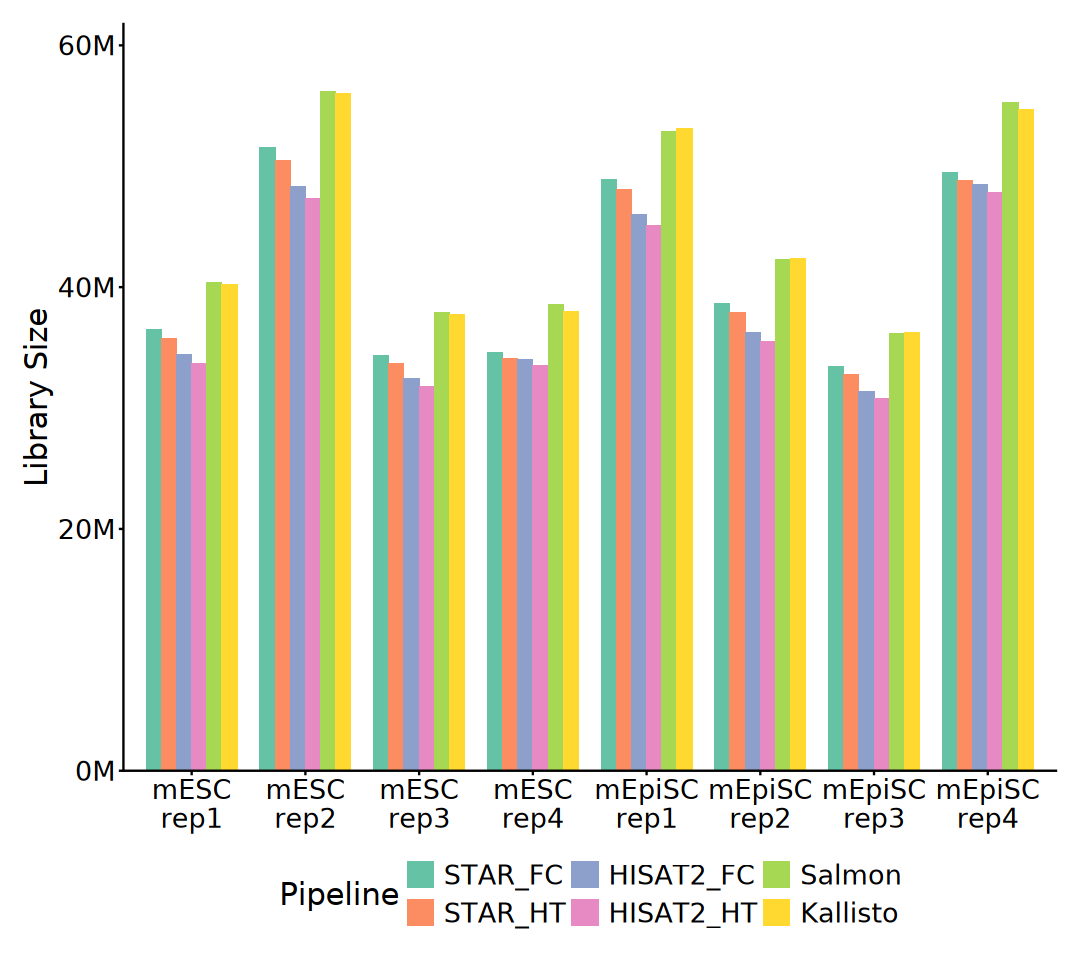

In [37]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = Sample, y = librarySize)) +
    geom_bar(
        aes(fill = Pipeline), stat = "identity", 
        position = position_dodge(width = 0.8), width = 0.8) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [38]:
top_var_idx <- combined_norm |> rowSds() |>
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 1000) |>
    pull(row)

In [39]:
pca_res <- combined_norm[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- pca_res$x[, 1:3] |> as.data.frame() |> 
    rownames_to_column("sample") |>
    separate(
        col = sample, into = c("Cell", "Replicate", "Pipeline"), 
        sep = "_", fill = "right", extra = "merge", remove = FALSE) |>
    mutate( 
        Cell = factor(Cell, levels = c("mESC", "mEpiSC")), 
        Pipeline = factor(Pipeline, levels = names(dds_list)),
        Replicate = factor(Replicate)) |> 
    column_to_rownames("sample")

head(pca_df)

,Cell,Replicate,Pipeline,PC1,PC2,PC3
,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
mESC_rep1_STAR_FC,mESC,rep1,STAR_FC,-43.79928,-22.37772,17.752194
mESC_rep2_STAR_FC,mESC,rep2,STAR_FC,-31.99876,-20.81200,14.247669
mESC_rep3_STAR_FC,mESC,rep3,STAR_FC,-51.98172,-21.45152,-3.210620
mESC_rep4_STAR_FC,mESC,rep4,STAR_FC,-50.03361,-27.80423,-17.661599
mEpiSC_rep1_STAR_FC,mEpiSC,rep1,STAR_FC,55.86380,-12.66506,11.877161
mEpiSC_rep2_STAR_FC,mEpiSC,rep2,STAR_FC,48.75999,-13.59618,3.354598


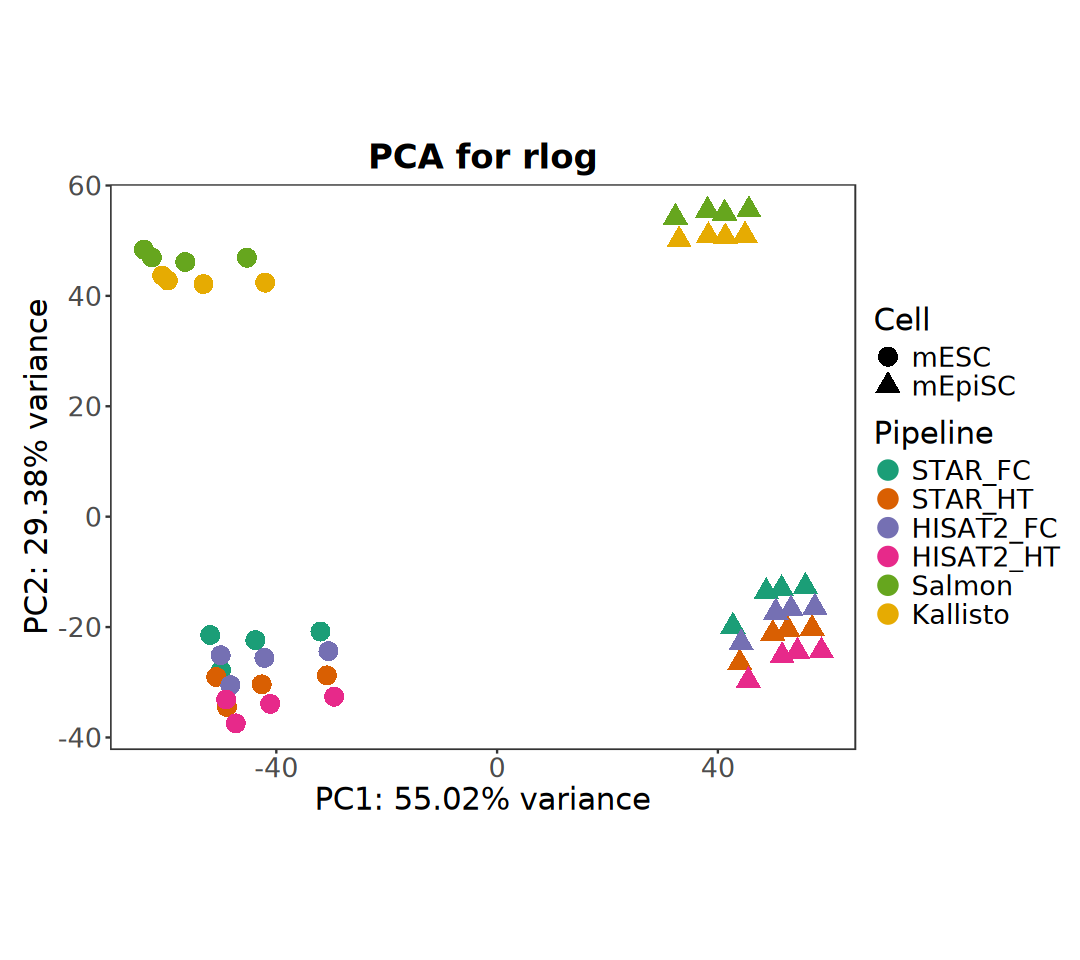

In [40]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Pipeline, shape = Cell), size = 5) +
    scale_color_brewer(palette = "Dark2") +
    coord_fixed() + 
    labs(
        title = "PCA for rlog", , 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 3). Sample Distance

In [41]:
ac <- pca_df |> dplyr::select(Replicate, Pipeline, Cell)

In [42]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(ac$Cell)),
    levels(ac$Cell))
pipeline_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(ac$Pipeline)),
    levels(ac$Pipeline))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set3")(nlevels(ac$Replicate)),
    levels(ac$Replicate))

anno_colors <- list(
    Cell = group_colors,
    Pipeline = pipeline_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [43]:
dist_mat <- combined_norm[top_var_idx, ] |> t() |> dist()

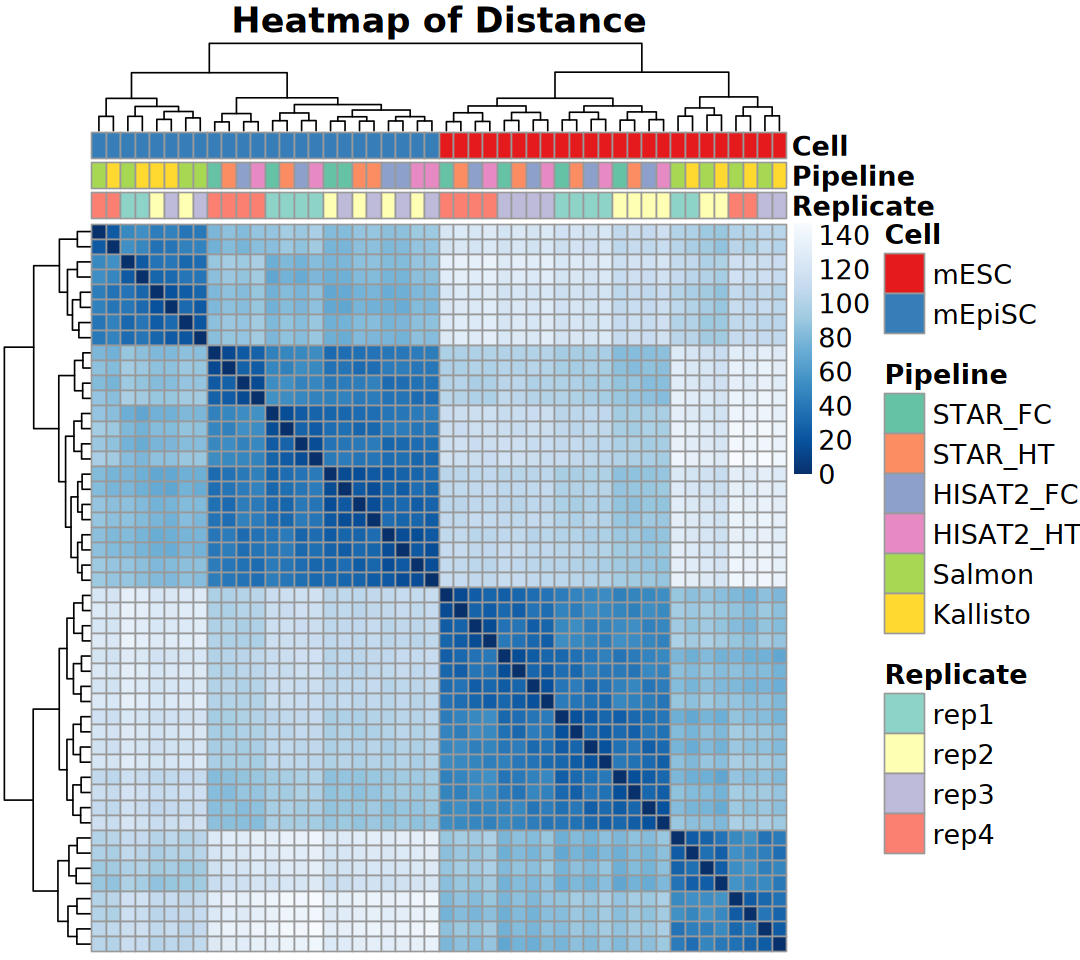

In [44]:
options(repr.plot.width = 9, repr.plot.height = 8)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 4). Sample Correlation

In [45]:
cor_mat <- cor(combined_norm[top_var_idx, ], method = "spearman")

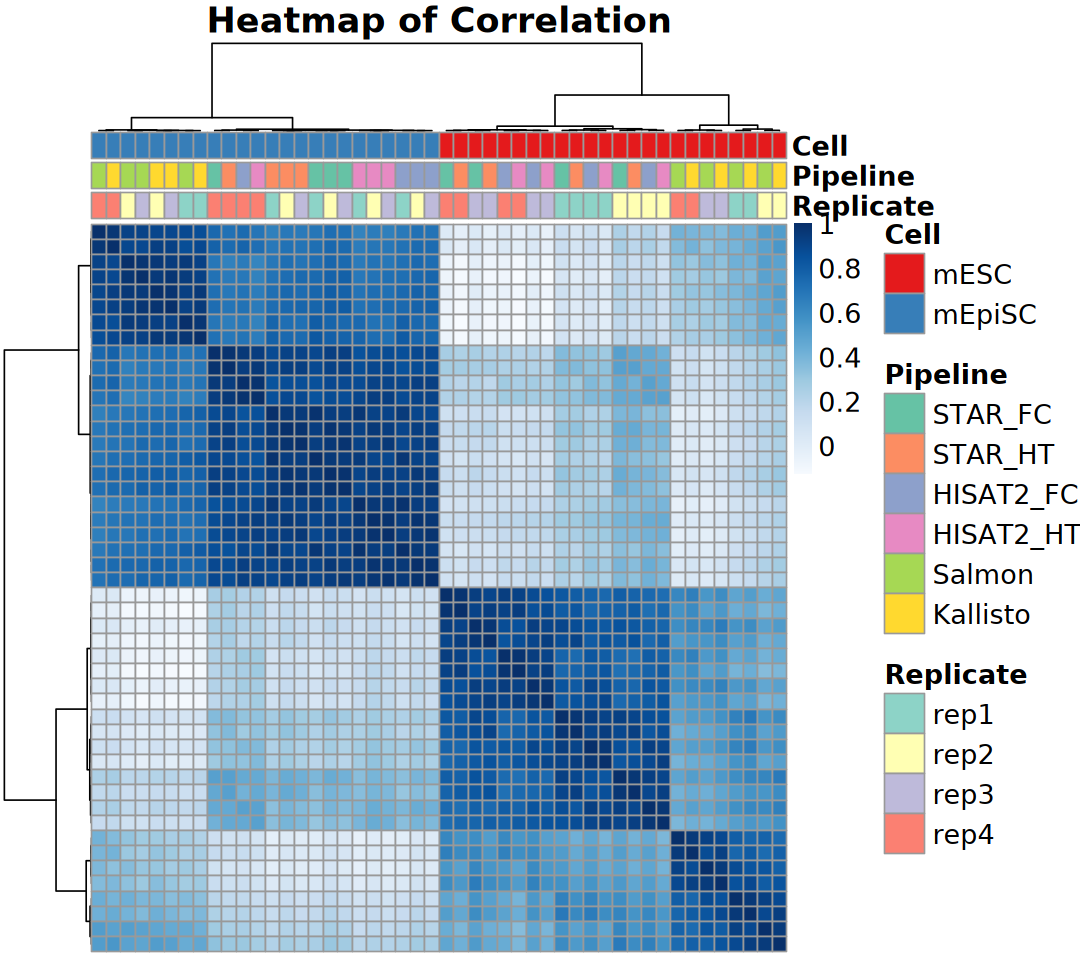

In [46]:
options(repr.plot.width = 9, repr.plot.height = 8)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 5). Heatmap

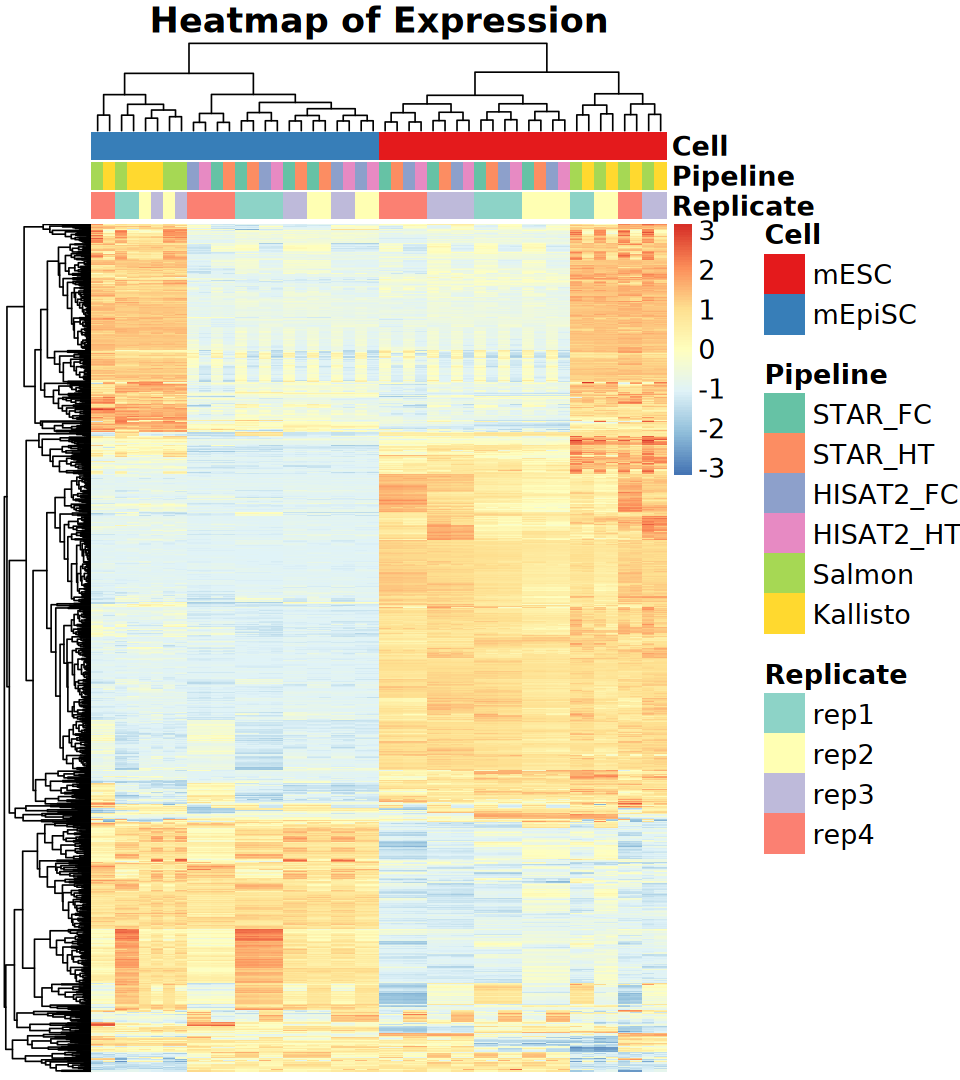

In [47]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    combined_norm[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs: DESeq2

In [48]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

In [49]:
result_list <- lapply(dds_list, function(dds) {
    design(dds) <- ~ Cell
    dds <- DESeq(dds)
    res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
    res |> as.data.frame() |> 
        dplyr::rename(logFC = log2FoldChange) |>
        mutate(
            result = case_when(
                padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
                padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
                TRUE ~ "NS") |> 
                factor(levels = c("Up", "Down", "NS")))
})

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating 

### Evaluate DEGs

In [50]:
suppressPackageStartupMessages(library(UpSetR))

In [51]:
genes_up <- lapply(result_list, function(res) {
    res |> rownames_to_column("Geneid") |> 
        filter(result == "Up") |> 
        pull(Geneid) |> unique()
})

genes_down <- lapply(result_list, function(res) {
    res |> rownames_to_column("Geneid") |> 
        filter(result == "Down") |> 
        pull(Geneid) |> unique()
})

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue at <https://github.com/hms-dbmi/UpSetR/issues>.”


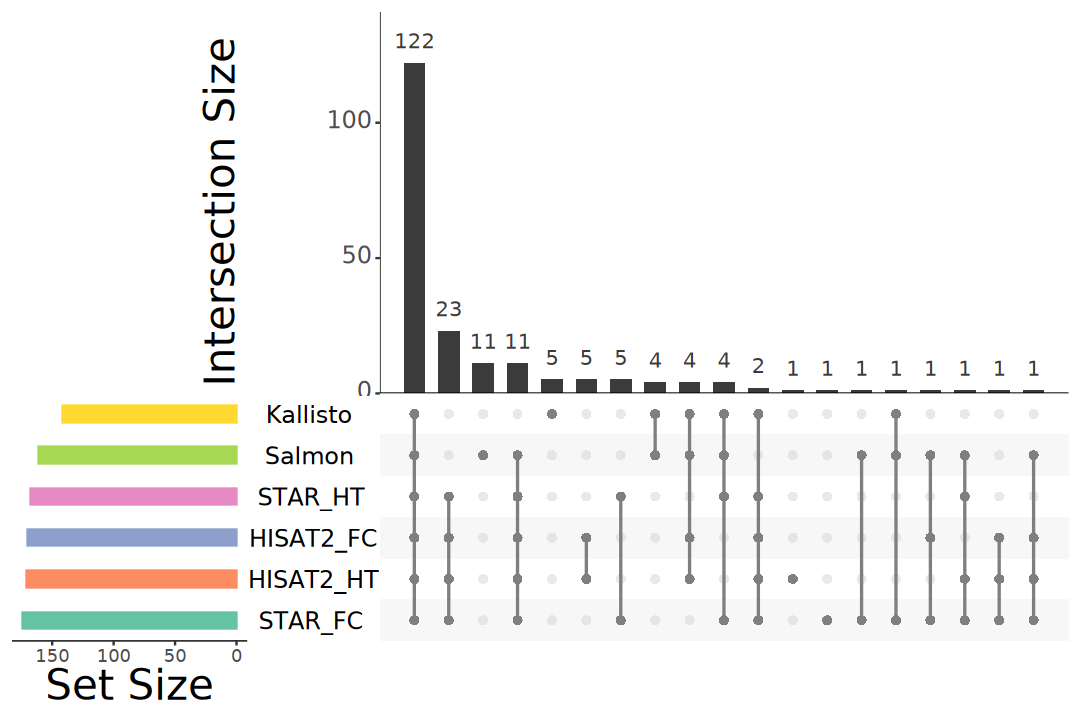

In [52]:
options(repr.plot.width = 9, repr.plot.height = 6)

UpSetR::upset(
    fromList(genes_up), nsets = 6, mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 6, name = "Set2"),
    # main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

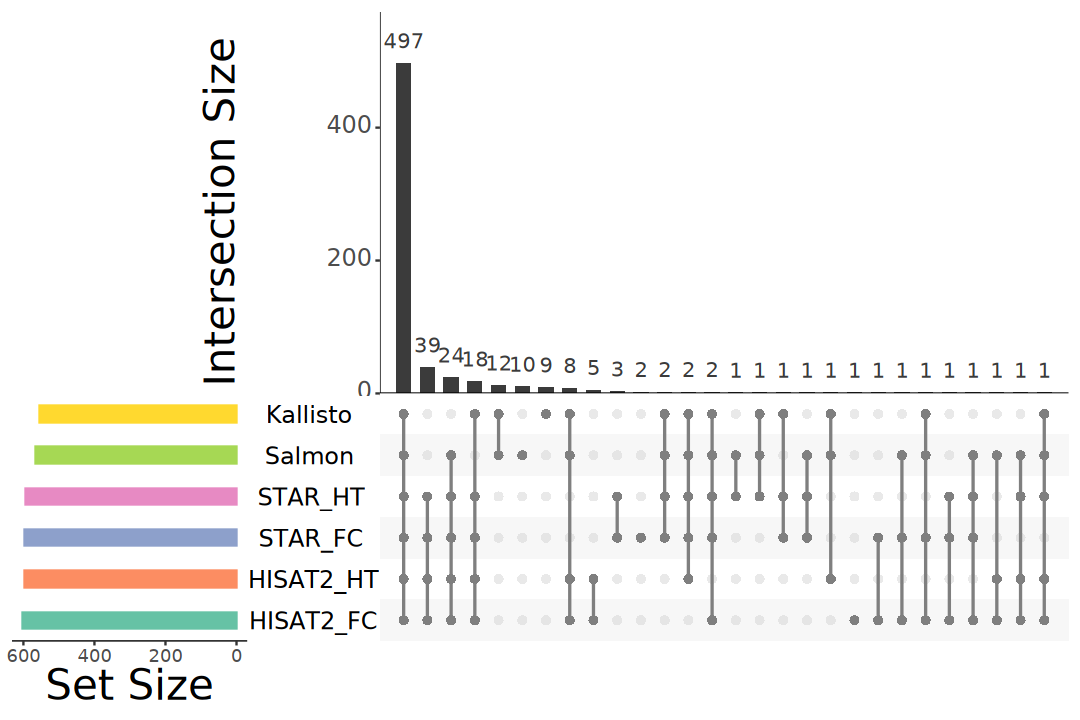

In [53]:
options(repr.plot.width = 9, repr.plot.height = 6)

UpSetR::upset(
    fromList(genes_down), nsets = 6, mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 6, name = "Set2"),
    # main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)